# CS7643 Project – Run All Experiments 🚀

This notebook will:

1. Check the environment (PyTorch, CUDA, CUDA-Q)
2. Add `src/` to `sys.path`
3. Run classical + hybrid experiments via `experiments/run_experiments.py`
4. Train the Quantum ViT with CUDA-Q self-attention
5. Generate plots from all CSV logs


In [1]:
import os, sys, torch
print('Working directory:', os.getcwd())
print('Python executable:', sys.executable)
print('PyTorch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('CUDA device:', torch.cuda.get_device_name(0))
try:
    import cudaq
    print('CUDA-Q version:', cudaq.__version__)
    print('CUDA-Q targets:', cudaq.get_targets())
except Exception as e:
    print('Warning: CUDA-Q not fully available or misconfigured:', e)


Working directory: /home/daisy/Downloads/cs7643_project_quantum trandformer
Python executable: /home/daisy/miniconda3/envs/cs7643_project/bin/python
PyTorch version: 2.9.1+cu128
CUDA available: True
CUDA device: NVIDIA GeForce RTX 5090
CUDA-Q version: CUDA-Q Version 0.13.0 (https://github.com/NVIDIA/cuda-quantum b66c5bb7fd8c08e5014e2f03e97e7b0e92691650)
CUDA-Q targets: [<cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x788831ba3bf0>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x7883d73238f0>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x7887877bf730>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x7883d7328b30>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x7883d734d0f0>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x788634199870>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x7886341905b0>, <cudaq.mlir._mlir_libs._q

In [2]:
import os, sys
project_root = os.getcwd()
src_path = os.path.join(project_root, 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
print('Project root:', project_root)
print('Added to sys.path:', src_path)
try:
    import data_utils, models
    print('✅ Imported data_utils and models successfully.')
except Exception as e:
    print('❌ Import error:', e)


Project root: /home/daisy/Downloads/cs7643_project_quantum trandformer
Added to sys.path: /home/daisy/Downloads/cs7643_project_quantum trandformer/src
[CUDA-Q] Using target: nvidia-mqpu-fp64
[warning] Target nvidia-mqpu-fp64: This target is deprecating. Please use the 'nvidia' target with option 'mqpu,fp64' by adding the command line option '--target-option mqpu,fp64' or passing it as cudaq.set_target('nvidia', option='mqpu,fp64') in Python. Please refer to CUDA-Q ]8;;https://nvidia.github.io/cuda-quantum/latest/using/backends/platform.html#nvidia-mqpu-platform\documentation]8;;\ for more information.
[CUDA-Q] (attention) Using target: nvidia-mqpu-fp64
[warning] Target nvidia-mqpu-fp64: This target is deprecating. Please use the 'nvidia' target with option 'mqpu,fp64' by adding the command line option '--target-option mqpu,fp64' or passing it as cudaq.set_target('nvidia', option='mqpu,fp64') in Python. Please refer to CUDA-Q ]8;;https://nvidia.github.io/cuda-quantum/latest/using/b

In [4]:
import os

print("CWD:", os.getcwd())
print("results exists?", os.path.exists("results"))
print("checkpoints exists?", os.path.exists("checkpoints"))
print("logs exists?", os.path.exists("logs"))
print("figures exists?", os.path.exists("figures"))


CWD: /home/daisy/Downloads/cs7643_project_quantum trandformer
results exists? True
checkpoints exists? True
logs exists? True
figures exists? True


In [5]:
import os

# Change into src so that ../results, ../checkpoints, ../logs
# all point back to the project root directories
os.chdir("src")
print("New CWD:", os.getcwd())


New CWD: /home/daisy/Downloads/cs7643_project_quantum trandformer/src


In [6]:
from experiments.run_experiments import main as run_all_experiments
run_all_experiments()


[classical_cnn] Using device: cuda


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 317kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.41MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 2.69MB/s]


[✓] Initialized CSV log: ../results/classical_cnn.csv


[classical_cnn] Epoch 1/5: 100%|██████████| 938/938 [00:02<00:00, 360.00it/s, loss=2.31]


[classical_cnn][Epoch 1] train_loss=2.3042 val_loss=2.3028 val_acc=0.1000
[✓] Saved checkpoint: ../checkpoints/classical_cnn_best.pt


[classical_cnn] Epoch 2/5: 100%|██████████| 938/938 [00:02<00:00, 439.85it/s, loss=2.31]


... (25 outputs left out)

[hybrid_vit] Epoch 2/3: 100%|██████████| 1875/1875 [05:10<00:00,  6.04it/s, loss=2.3] 


[hybrid_vit][Epoch 2] train_loss=2.3028 val_loss=2.3028 val_acc=0.1000


[hybrid_vit] Epoch 3/3: 100%|██████████| 1875/1875 [05:10<00:00,  6.04it/s, loss=2.3] 


[hybrid_vit][Epoch 3] train_loss=2.3029 val_loss=2.3026 val_acc=0.1000
[✓] Saved checkpoint: ../checkpoints/hybrid_vit_last.pt
[hybrid_vit] Saved best checkpoint to ../checkpoints/hybrid_vit_best.pt
[hybrid_vit] Saved last checkpoint to ../checkpoints/hybrid_vit_last.pt


In [7]:
from train_quantum_transformer import train as train_quantum_vit
print('=== Training Quantum ViT with CUDA-Q self-attention ===')
train_quantum_vit(
    epochs=3,
    batch_size=32,
    lr=5e-4,
    run_name='quantum_vit_qattn',
    log_dir='../results',
    ckpt_dir='../checkpoints',
    txt_log_dir='../logs',
)
print('=== Finished Quantum ViT training ===')


=== Training Quantum ViT with CUDA-Q self-attention ===
[QuantumViT] Using device: cuda
[✓] Initialized CSV log: ../results/quantum_vit_qattn.csv


[QuantumViT] Epoch 1/3: 100%|██████████| 1875/1875 [36:21<00:00,  1.16s/it, loss=0.48] 


[QuantumViT Epoch 1] train_loss=0.7396 val_loss=0.5138 val_acc=0.8184
[✓] Saved checkpoint: ../checkpoints/quantum_vit_qattn_best.pt


[QuantumViT] Epoch 2/3: 100%|██████████| 1875/1875 [36:23<00:00,  1.16s/it, loss=0.485]


[QuantumViT Epoch 2] train_loss=0.4884 val_loss=0.4588 val_acc=0.8387
[✓] Saved checkpoint: ../checkpoints/quantum_vit_qattn_best.pt


[QuantumViT] Epoch 3/3: 100%|██████████| 1875/1875 [36:26<00:00,  1.17s/it, loss=0.594]


[QuantumViT Epoch 3] train_loss=0.4395 val_loss=0.4346 val_acc=0.8410
[✓] Saved checkpoint: ../checkpoints/quantum_vit_qattn_best.pt
[✓] Saved checkpoint: ../checkpoints/quantum_vit_qattn_last.pt
[QuantumViT] Saved best checkpoint to ../checkpoints/quantum_vit_qattn_best.pt
[QuantumViT] Saved last checkpoint to ../checkpoints/quantum_vit_qattn_last.pt
=== Finished Quantum ViT training ===


=== Generating plots from CSV logs ===
Saved plots to:
  ../results/loss_curves.png
  ../figures/loss_curves.png
  ../results/val_accuracy.png
  ../figures/val_accuracy.png
=== Done. Check '../results' and '../figures' for PNGs. ===


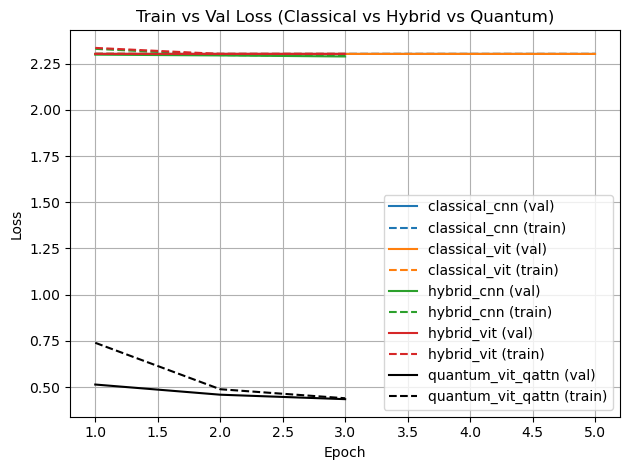

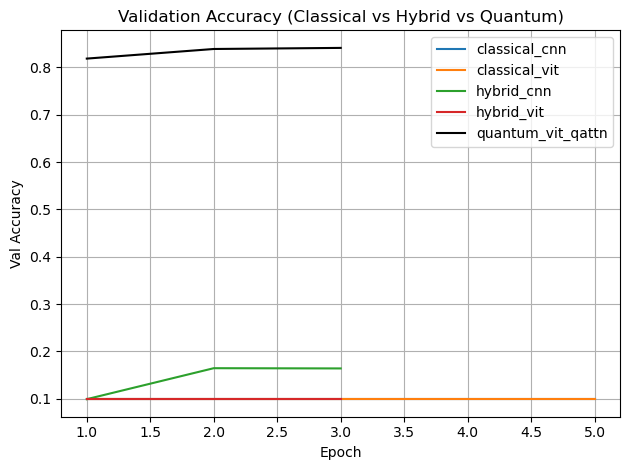

In [8]:
from experiments.plot_results import main as plot_all
print('=== Generating plots from CSV logs ===')
plot_all()
print("=== Done. Check '../results' and '../figures' for PNGs. ===")
